<center><h1>bagai_sanchit_HW5</h1></center>


Name: Sanchit Bagai
<br>
Github Username: baked-potatoes
<br>
USC ID: 1033382623

## 1. Decision Trees as Interpretable Models

Import packages

In [1]:
import numpy as np
import pandas as pd
import warnings
warnings.filterwarnings("ignore")

import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.tree import DecisionTreeClassifier, plot_tree, export_text
from sklearn.tree import _tree
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import StandardScaler
from sklearn.pipeline import Pipeline, make_pipeline
from sklearn.model_selection import train_test_split, GridSearchCV, KFold, cross_val_score
from sklearn.linear_model import LinearRegression, Ridge, RidgeCV, Lasso, LassoCV
from sklearn.decomposition import PCA
from sklearn.metrics import mean_squared_error, accuracy_score

import xgboost as xgb

### (a) Obtain Data

Get the Accute Inamations Data Set

In [2]:
path = "../data/diagnosis.data"

cols = [
    "temperature",
    "nausea",
    "lumbar_pain",
    "urine_pushing",
    "micturition_pains",
    "burning_urethra",
    "bladder_inflammation",
    "nephritis",
]

df = pd.read_csv(path, sep="\t", header=None, names=cols, encoding="utf-16", decimal=",")

df = df.replace({"yes": 1, "no": 0})

print(df.shape)
df.head()

(120, 8)


,temperature,nausea,lumbar_pain,urine_pushing,micturition_pains,burning_urethra,bladder_inflammation,nephritis
0,35.5,0,1,0,0,0,0,0
1,35.9,0,0,1,1,1,1,0
2,35.9,0,1,0,0,0,0,0
3,36.0,0,0,1,1,1,1,0
4,36.0,0,1,0,0,0,0,0


### (b) Build a decision tree

1_0    40
0_1    31
0_0    30
1_1    19
Name: count, dtype: int64
Training accuracy: 1.0
Depth: 4 | Leaves: 6


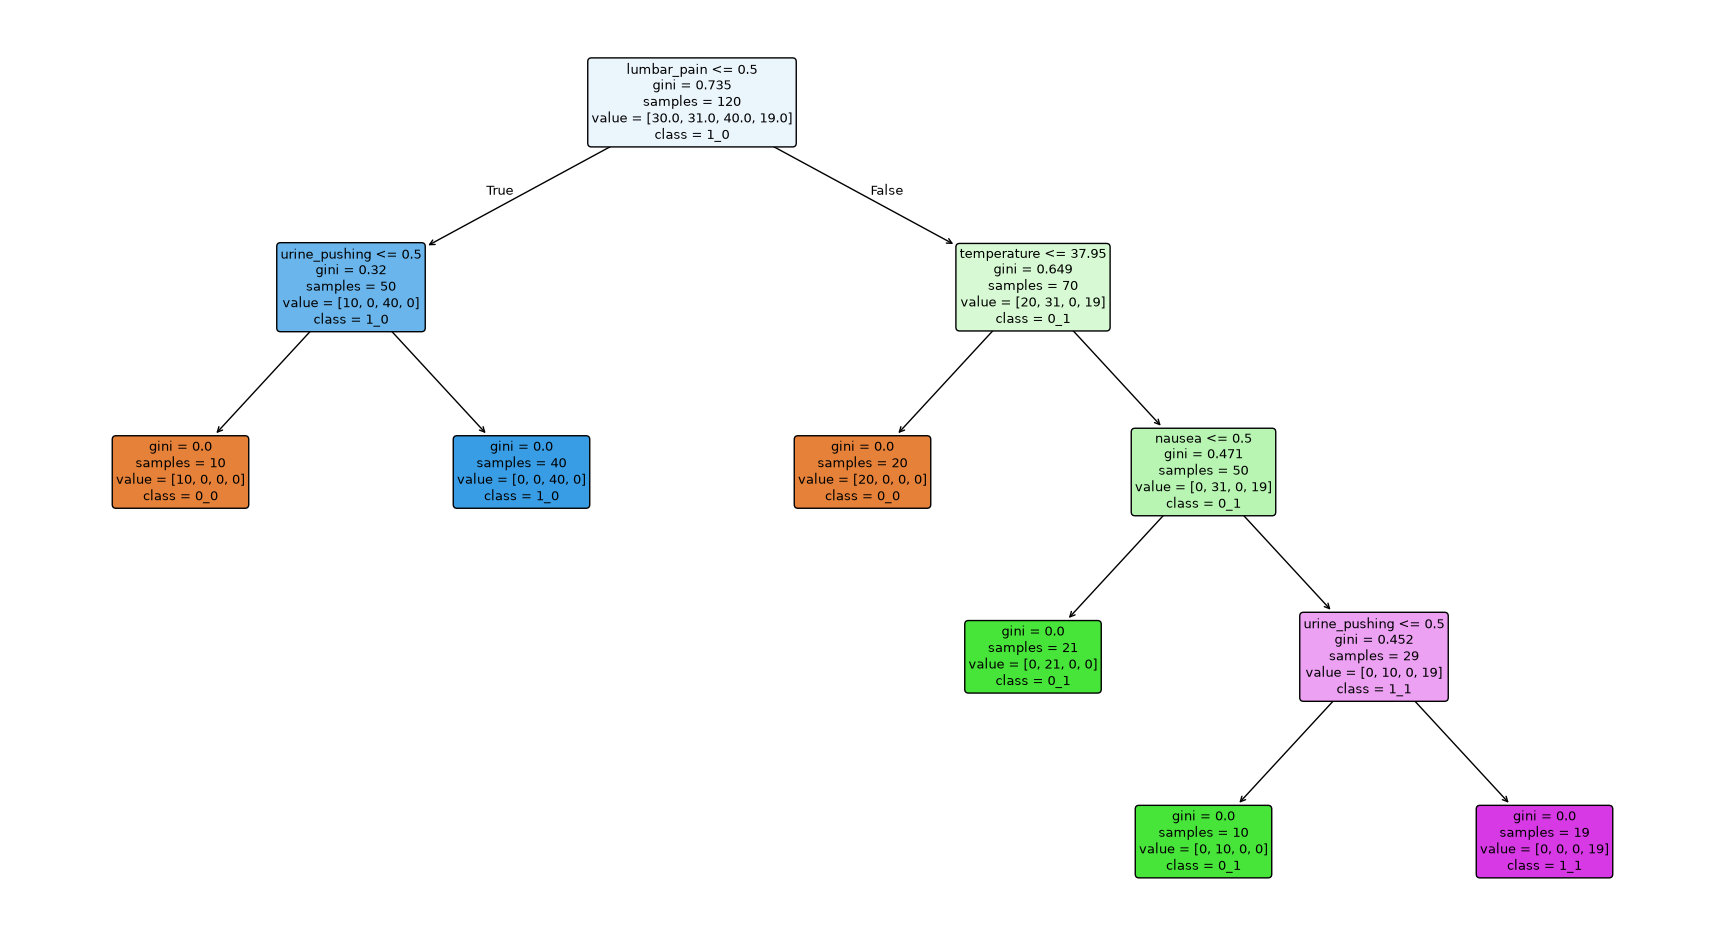

In [3]:
X = df.drop(columns=["bladder_inflammation", "nephritis"])
y = df["bladder_inflammation"].astype(str) + "_" + df["nephritis"].astype(str)

print(y.value_counts())

clf = DecisionTreeClassifier(random_state=42)
clf.fit(X, y)

print("Training accuracy:", accuracy_score(y, clf.predict(X)))
print("Depth:", clf.get_depth(), "| Leaves:", clf.get_n_leaves())

plt.figure(figsize=(22, 12))
plot_tree(
    clf,
    feature_names=X.columns,
    class_names=clf.classes_,
    filled=True,
    rounded=True,
    fontsize=9,
)
plt.show()

### (c) Convert the decision rules

In [4]:
def tree_to_rules(model, feature_names):
    tree_ = model.tree_
    classes = model.classes_
    rules = []

    def recurse(node, conditions):
        if tree_.feature[node] != _tree.TREE_UNDEFINED:
            name = feature_names[tree_.feature[node]]
            threshold = tree_.threshold[node]
            recurse(tree_.children_left[node], conditions + [f"{name} <= {threshold:.2f}"])
            recurse(tree_.children_right[node], conditions + [f"{name} > {threshold:.2f}"])
        else:
            label = classes[np.argmax(tree_.value[node][0])]
            rules.append((conditions, label, int(tree_.n_node_samples[node])))

    recurse(0, [])
    return rules

rules = tree_to_rules(clf, list(X.columns))
print(export_text(clf, feature_names=list(X.columns)))

for i, (conditions, label, n) in enumerate(rules, 1):
    print(f"Rule {i}: IF " + " AND ".join(conditions) + f" THEN class = {label}  ({n} samples)")

|--- lumbar_pain <= 0.50
|   |--- urine_pushing <= 0.50
|   |   |--- class: 0_0
|   |--- urine_pushing >  0.50
|   |   |--- class: 1_0
|--- lumbar_pain >  0.50
|   |--- temperature <= 37.95
|   |   |--- class: 0_0
|   |--- temperature >  37.95
|   |   |--- nausea <= 0.50
|   |   |   |--- class: 0_1
|   |   |--- nausea >  0.50
|   |   |   |--- urine_pushing <= 0.50
|   |   |   |   |--- class: 0_1
|   |   |   |--- urine_pushing >  0.50
|   |   |   |   |--- class: 1_1

Rule 1: IF lumbar_pain <= 0.50 AND urine_pushing <= 0.50 THEN class = 0_0  (10 samples)
Rule 2: IF lumbar_pain <= 0.50 AND urine_pushing > 0.50 THEN class = 1_0  (40 samples)
Rule 3: IF lumbar_pain > 0.50 AND temperature <= 37.95 THEN class = 0_0  (20 samples)
Rule 4: IF lumbar_pain > 0.50 AND temperature > 37.95 AND nausea <= 0.50 THEN class = 0_1  (21 samples)
Rule 5: IF lumbar_pain > 0.50 AND temperature > 37.95 AND nausea > 0.50 AND urine_pushing <= 0.50 THEN class = 0_1  (10 samples)
Rule 6: IF lumbar_pain > 0.50 AND t

### (d) Cost-complexity pruning

Best ccp_alpha: 0.0 | CV accuracy: 0.9916666666666668


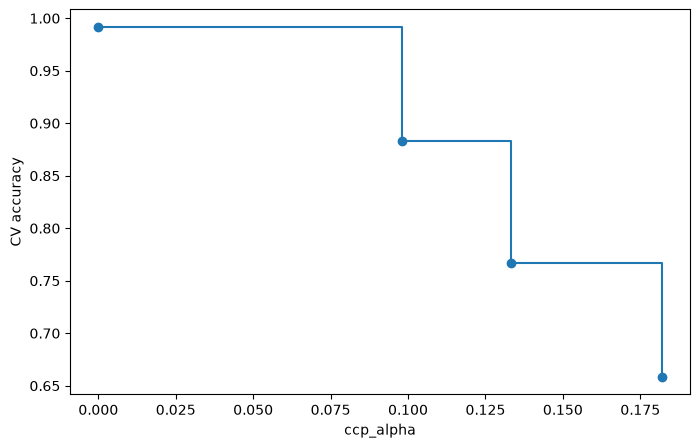

Chosen ccp_alpha: 0.0
Depth: 4 | Leaves: 6
Training accuracy: 1.0


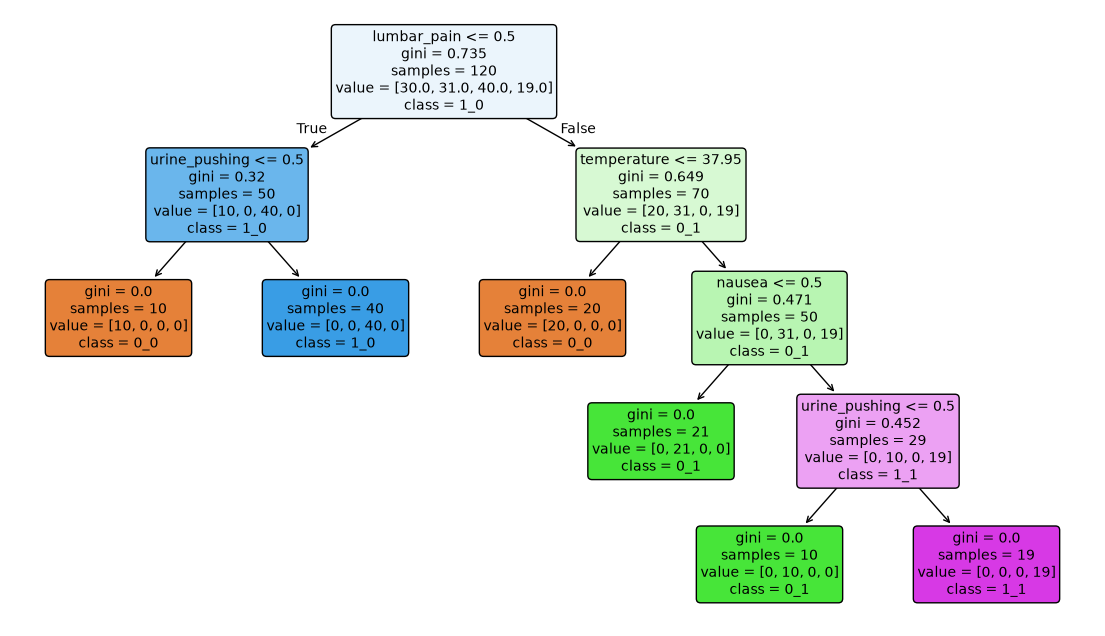

|--- lumbar_pain <= 0.50
|   |--- urine_pushing <= 0.50
|   |   |--- class: 0_0
|   |--- urine_pushing >  0.50
|   |   |--- class: 1_0
|--- lumbar_pain >  0.50
|   |--- temperature <= 37.95
|   |   |--- class: 0_0
|   |--- temperature >  37.95
|   |   |--- nausea <= 0.50
|   |   |   |--- class: 0_1
|   |   |--- nausea >  0.50
|   |   |   |--- urine_pushing <= 0.50
|   |   |   |   |--- class: 0_1
|   |   |   |--- urine_pushing >  0.50
|   |   |   |   |--- class: 1_1

Rule 1: IF lumbar_pain <= 0.50 AND urine_pushing <= 0.50 THEN class = 0_0  (10 samples)
Rule 2: IF lumbar_pain <= 0.50 AND urine_pushing > 0.50 THEN class = 1_0  (40 samples)
Rule 3: IF lumbar_pain > 0.50 AND temperature <= 37.95 THEN class = 0_0  (20 samples)
Rule 4: IF lumbar_pain > 0.50 AND temperature > 37.95 AND nausea <= 0.50 THEN class = 0_1  (21 samples)
Rule 5: IF lumbar_pain > 0.50 AND temperature > 37.95 AND nausea > 0.50 AND urine_pushing <= 0.50 THEN class = 0_1  (10 samples)
Rule 6: IF lumbar_pain > 0.50 AND t

In [5]:
path_alphas = clf.cost_complexity_pruning_path(X, y)
ccp_alphas = path_alphas.ccp_alphas[:-1]

cv = KFold(n_splits=5, shuffle=True, random_state=42)

scores = []
for a in ccp_alphas:
    m = DecisionTreeClassifier(random_state=42, ccp_alpha=a)
    scores.append(cross_val_score(m, X, y, cv=cv).mean())

best_alpha = ccp_alphas[int(np.argmax(scores))]
print("Best ccp_alpha:", best_alpha, "| CV accuracy:", max(scores))

plt.figure(figsize=(8, 5))
plt.plot(ccp_alphas, scores, marker="o", drawstyle="steps-post")
plt.xlabel("ccp_alpha")
plt.ylabel("CV accuracy")
plt.show()

fold_scores = []
for a in ccp_alphas:
    m = DecisionTreeClassifier(random_state=42, ccp_alpha=a)
    fold_scores.append(cross_val_score(m, X, y, cv=cv))

means = np.array([s.mean() for s in fold_scores])
sems = np.array([s.std(ddof=1) / np.sqrt(len(s)) for s in fold_scores])

best_idx = int(np.argmax(means))
threshold = means[best_idx] - sems[best_idx]
chosen_alpha = max(a for a, mu in zip(ccp_alphas, means) if mu >= threshold)

pruned = DecisionTreeClassifier(random_state=42, ccp_alpha=chosen_alpha)
pruned.fit(X, y)

print("Chosen ccp_alpha:", chosen_alpha)
print("Depth:", pruned.get_depth(), "| Leaves:", pruned.get_n_leaves())
print("Training accuracy:", accuracy_score(y, pruned.predict(X)))

plt.figure(figsize=(14, 8))
plot_tree(
    pruned,
    feature_names=X.columns,
    class_names=pruned.classes_,
    filled=True,
    rounded=True,
    fontsize=10,
)
plt.show()

pruned_rules = tree_to_rules(pruned, list(X.columns))
print(export_text(pruned, feature_names=list(X.columns)))

for i, (conditions, label, n) in enumerate(pruned_rules, 1):
    print(f"Rule {i}: IF " + " AND ".join(conditions) + f" THEN class = {label}  ({n} samples)")

The unpruned tree produced the highest cv accuracy of 0.9917. Cost-complexity pruning did not cut down the tree size because it wasn't able to reduce the size without substantial accuracy loss.

In [6]:
rows = []
for a, mu in zip(ccp_alphas, means):
    t = DecisionTreeClassifier(random_state=42, ccp_alpha=a).fit(X, y)
    rows.append({"ccp_alpha": a, "leaves": t.get_n_leaves(), "cv_accuracy": mu})

pd.DataFrame(rows)

,ccp_alpha,leaves,cv_accuracy
0,0.000000,6,0.991667
1,0.098167,4,0.883333
2,0.133333,3,0.766667
3,0.182000,2,0.658333


## 2. The LASSO and Boosting for Regression

### (a) Obtain Data

In [7]:
path = "../data/communities.data"

cols = [
    "state", "county", "community", "communityname", "fold",
    "population", "householdsize", "racepctblack", "racePctWhite", "racePctAsian",
    "racePctHisp", "agePct12t21", "agePct12t29", "agePct16t24", "agePct65up",
    "numbUrban", "pctUrban", "medIncome", "pctWWage", "pctWFarmSelf",
    "pctWInvInc", "pctWSocSec", "pctWPubAsst", "pctWRetire", "medFamInc",
    "perCapInc", "whitePerCap", "blackPerCap", "indianPerCap", "AsianPerCap",
    "OtherPerCap", "HispPerCap", "NumUnderPov", "PctPopUnderPov", "PctLess9thGrade",
    "PctNotHSGrad", "PctBSorMore", "PctUnemployed", "PctEmploy", "PctEmplManu",
    "PctEmplProfServ", "PctOccupManu", "PctOccupMgmtProf", "MalePctDivorce", "MalePctNevMarr",
    "FemalePctDiv", "TotalPctDiv", "PersPerFam", "PctFam2Par", "PctKids2Par",
    "PctYoungKids2Par", "PctTeen2Par", "PctWorkMomYoungKids", "PctWorkMom", "NumIlleg",
    "PctIlleg", "NumImmig", "PctImmigRecent", "PctImmigRec5", "PctImmigRec8",
    "PctImmigRec10", "PctRecentImmigrant", "PctRecImmig5", "PctRecImmig8", "PctRecImmig10",
    "PctSpeakEnglOnly", "PctNotSpeakEnglWell", "PctLargHouseFam", "PctLargHouseOccup", "PersPerOccupHous",
    "PersPerOwnOccHous", "PersPerRentOccHous", "PctPersOwnOccup", "PctPersDenseHous", "PctHousLess3BR",
    "MedNumBR", "HousVacant", "PctHousOccup", "PctHousOwnOcc", "PctVacantBoarded",
    "PctVacMore6Mos", "MedYrHousBuilt", "PctHousNoPhone", "PctWOFullPlumb", "OwnOccLowQuart",
    "OwnOccMedVal", "OwnOccHiQuart", "RentLowQ", "RentMedian", "RentHighQ",
    "MedRent", "MedRentPctHousInc", "MedOwnCostPctInc", "MedOwnCostPctIncNoMtg", "NumInShelters",
    "NumStreet", "PctForeignBorn", "PctBornSameState", "PctSameHouse85", "PctSameCity85",
    "PctSameState85", "LemasSwornFT", "LemasSwFTPerPop", "LemasSwFTFieldOps", "LemasSwFTFieldPerPop",
    "LemasTotalReq", "LemasTotReqPerPop", "PolicReqPerOffic", "PolicPerPop", "RacialMatchCommPol",
    "PctPolicWhite", "PctPolicBlack", "PctPolicHisp", "PctPolicAsian", "PctPolicMinor",
    "OfficAssgnDrugUnits", "NumKindsDrugsSeiz", "PolicAveOTWorked", "LandArea", "PopDens",
    "PctUsePubTrans", "PolicCars", "PolicOperBudg", "LemasPctPolicOnPatr", "LemasGangUnitDeploy",
    "LemasPctOfficDrugUn", "PolicBudgPerPop", "ViolentCrimesPerPop",
]

crime = pd.read_csv(path, header=None, names=cols, na_values="?")

train_raw = crime.iloc[:1495].copy()
test_raw = crime.iloc[1495:].copy()

print(crime.shape)
print("Train:", train_raw.shape, "| Test:", test_raw.shape)
crime.head()

(1994, 128)
Train: (1495, 128) | Test: (499, 128)


,state,county,community,communityname,fold,population,householdsize,racepctblack,racePctWhite,racePctAsian,...,LandArea,PopDens,PctUsePubTrans,PolicCars,PolicOperBudg,LemasPctPolicOnPatr,LemasGangUnitDeploy,LemasPctOfficDrugUn,PolicBudgPerPop,ViolentCrimesPerPop
0,8,NaN,NaN,Lakewoodcity,1,0.19,0.33,0.02,0.90,0.12,...,0.12,0.26,0.20,0.06,0.04,0.9,0.5,0.32,0.14,0.20
1,53,NaN,NaN,Tukwilacity,1,0.00,0.16,0.12,0.74,0.45,...,0.02,0.12,0.45,NaN,NaN,NaN,NaN,0.00,NaN,0.67
2,24,NaN,NaN,Aberdeentown,1,0.00,0.42,0.49,0.56,0.17,...,0.01,0.21,0.02,NaN,NaN,NaN,NaN,0.00,NaN,0.43
3,34,5.0,81440.0,Willingborotownship,1,0.04,0.77,1.00,0.08,0.12,...,0.02,0.39,0.28,NaN,NaN,NaN,NaN,0.00,NaN,0.12
4,42,95.0,6096.0,Bethlehemtownship,1,0.01,0.55,0.02,0.95,0.09,...,0.04,0.09,0.02,NaN,NaN,NaN,NaN,0.00,NaN,0.03


### (b) Missing values

In [8]:
nonpredictive = ["state", "county", "community", "communityname", "fold"]
target = "ViolentCrimesPerPop"

train_df = train_raw.drop(columns=nonpredictive)
test_df = test_raw.drop(columns=nonpredictive)

missing = train_df.isna().sum()
print("Columns with missing values (train):", (missing > 0).sum())
print(missing[missing > 0].sort_values(ascending=False).head(10))
print("Target missing:", train_df[target].isna().sum(), test_df[target].isna().sum())

X_train_raw = train_df.drop(columns=[target])
y_train = train_df[target]
X_test_raw = test_df.drop(columns=[target])
y_test = test_df[target]

imputer = SimpleImputer(strategy="mean")
X_train = pd.DataFrame(imputer.fit_transform(X_train_raw), columns=X_train_raw.columns, index=X_train_raw.index)
X_test = pd.DataFrame(imputer.transform(X_test_raw), columns=X_test_raw.columns, index=X_test_raw.index)

print(X_train.shape, X_test.shape)
print("Remaining NaNs:", X_train.isna().sum().sum(), X_test.isna().sum().sum())

Columns with missing values (train): 23
LemasSwornFT            1256
LemasSwFTPerPop         1256
LemasSwFTFieldOps       1256
LemasTotalReq           1256
LemasSwFTFieldPerPop    1256
LemasTotReqPerPop       1256
PolicReqPerOffic        1256
OfficAssgnDrugUnits     1256
PolicPerPop             1256
RacialMatchCommPol      1256
dtype: int64
Target missing: 0 0
(1495, 122) (499, 122)
Remaining NaNs: 0 0


### (c) Plot a correlation matrix

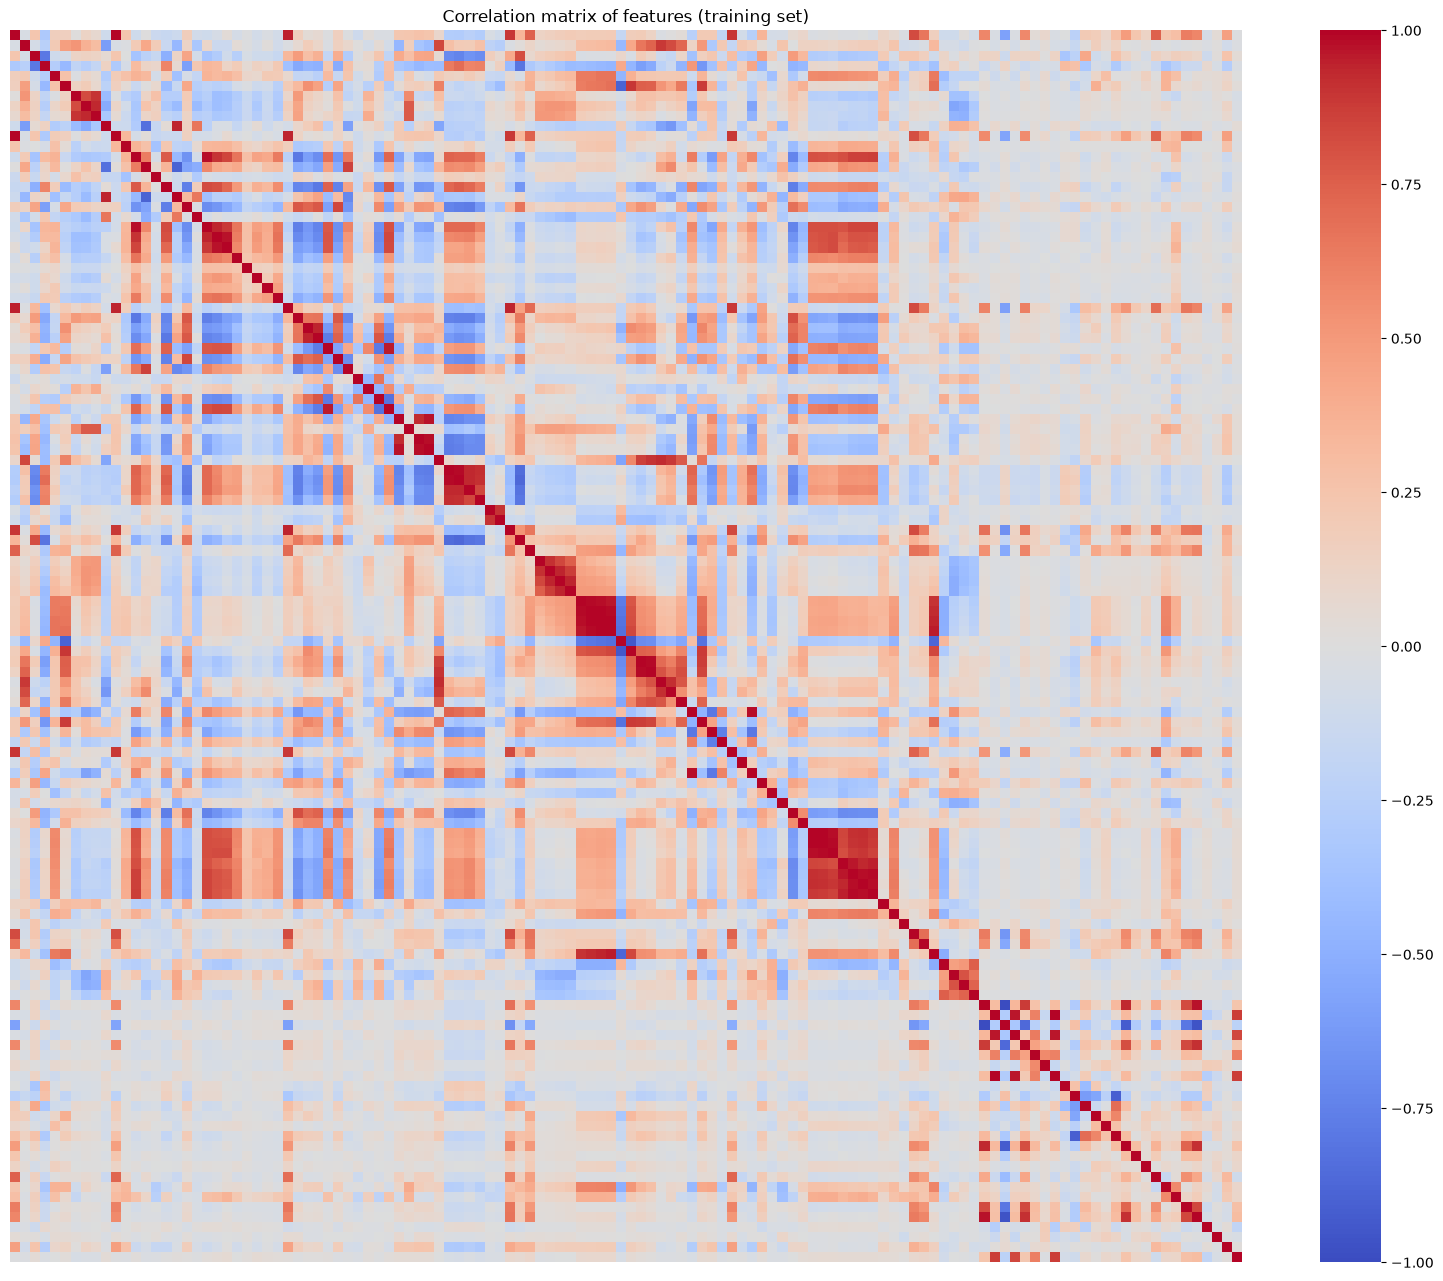

LemasSwFTPerPop     PolicPerPop          1.000000
PctRecImmig8        PctRecImmig10        0.995561
OwnOccLowQuart      OwnOccMedVal         0.994692
LemasSwornFT        LemasSwFTFieldOps    0.993998
population          numbUrban            0.993613
PctRecImmig5        PctRecImmig8         0.992735
OwnOccMedVal        OwnOccHiQuart        0.991559
PctRecentImmigrant  PctRecImmig5         0.989361
RentMedian          MedRent              0.988780
PctFam2Par          PctKids2Par          0.985623
dtype: float64


In [9]:
corr = X_train.corr()

plt.figure(figsize=(20, 16))
sns.heatmap(corr, cmap="coolwarm", center=0, vmin=-1, vmax=1, xticklabels=False, yticklabels=False, square=True)
plt.title("Correlation matrix of features (training set)")
plt.show()

pairs = corr.where(np.triu(np.ones(corr.shape, dtype=bool), k=1)).stack()
print(pairs.abs().sort_values(ascending=False).head(10))

### (d) Calculate the Coefficient of Variation CV

In [10]:
cv_values = X_train.std(ddof=1) / X_train.mean()

cv_df = pd.DataFrame({"mean": X_train.mean(), "std": X_train.std(ddof=1), "CV": cv_values})
cv_df = cv_df.reindex(cv_df["CV"].abs().sort_values(ascending=False).index)

print(cv_df.head(15))

                         mean       std        CV
NumStreet            0.022983  0.098665  4.292923
NumInShelters        0.029599  0.102736  3.470952
NumIlleg             0.037204  0.113806  3.058964
NumImmig             0.030595  0.089541  2.926635
LemasPctOfficDrugUn  0.093304  0.238201  2.552946
NumUnderPov          0.056849  0.133167  2.342443
population           0.058167  0.130359  2.241105
numbUrban            0.064649  0.131784  2.038461
HousVacant           0.076475  0.150538  1.968467
LandArea             0.064107  0.105482  1.645408
racePctHisp          0.144963  0.233694  1.612091
PctNotSpeakEnglWell  0.151880  0.221231  1.456618
racepctblack         0.179839  0.256970  1.428885
PctUsePubTrans       0.165197  0.230799  1.397110
racePctAsian         0.153712  0.208910  1.359100


### (e) Scatter plots and box plots for highest CV features

11 ['NumStreet', 'NumInShelters', 'NumIlleg', 'NumImmig', 'LemasPctOfficDrugUn', 'NumUnderPov', 'population', 'numbUrban', 'HousVacant', 'LandArea', 'racePctHisp']


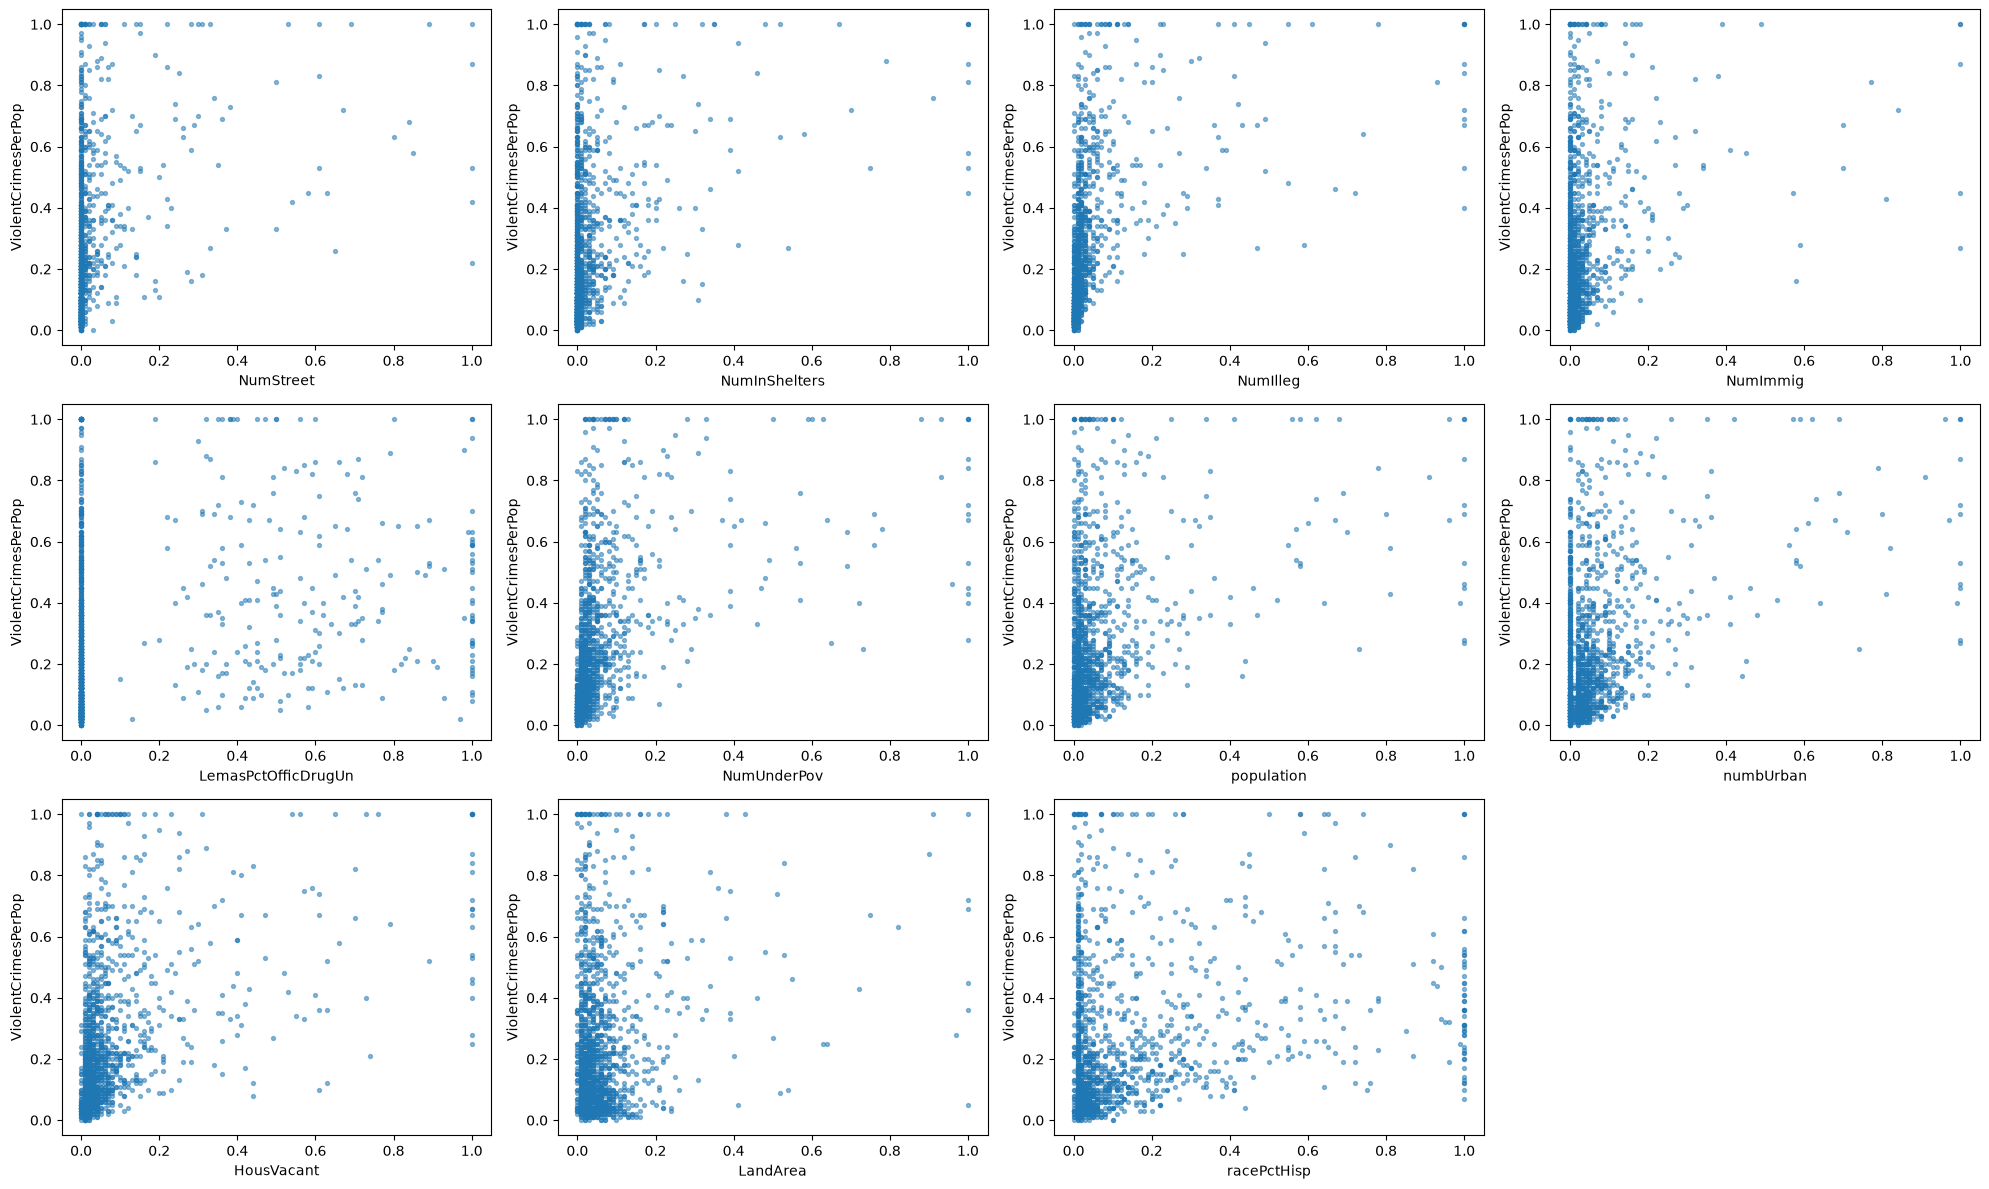

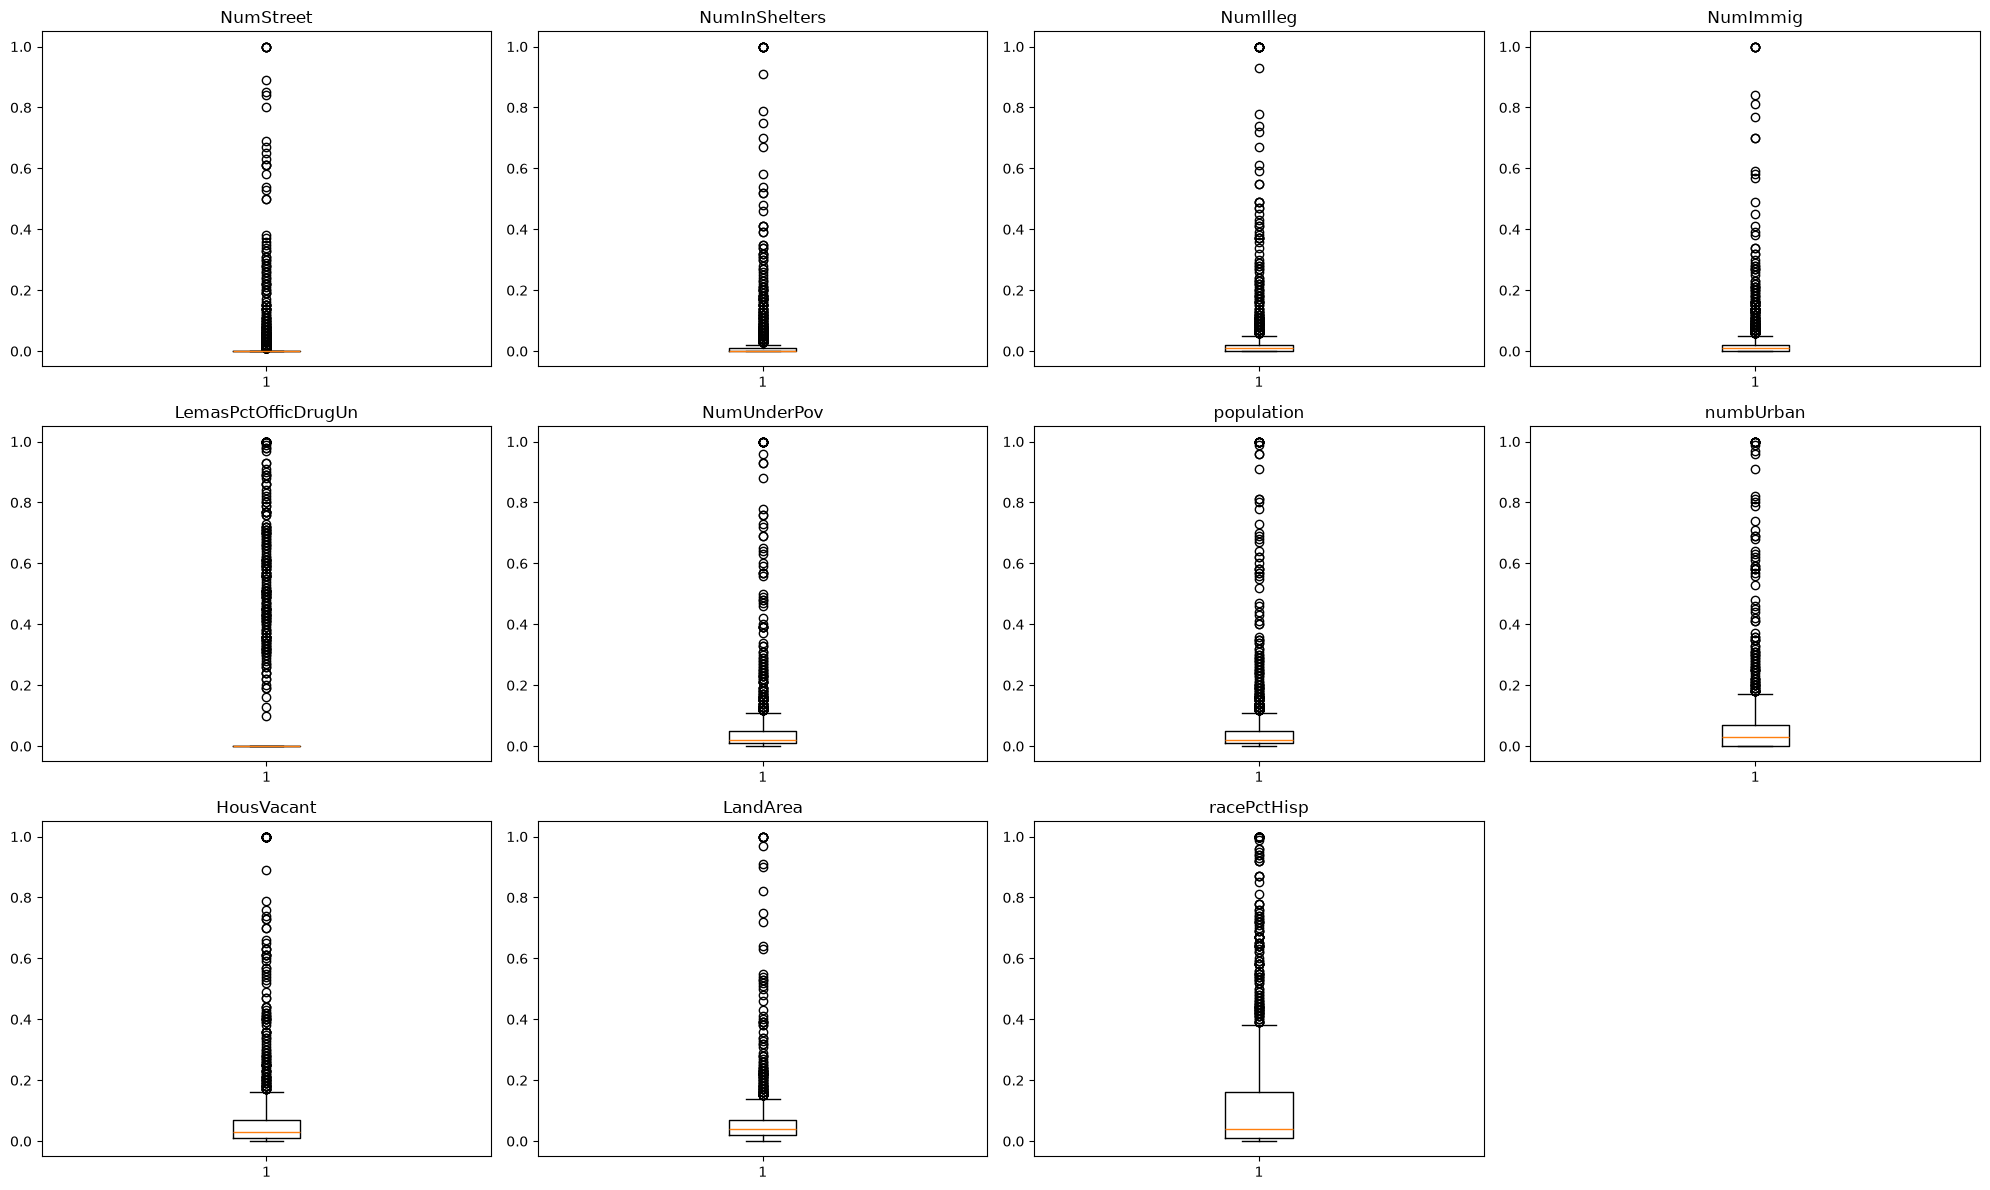

NumIlleg               0.462910
NumUnderPov            0.442259
HousVacant             0.422420
NumInShelters          0.372858
population             0.364245
numbUrban              0.361575
NumStreet              0.332321
LemasPctOfficDrugUn    0.331882
NumImmig               0.294710
racePctHisp            0.288889
LandArea               0.205028
dtype: float64


In [11]:
k = int(np.floor(np.sqrt(128)))
top_features = cv_df.head(k).index.tolist()
print(k, top_features)

fig, axes = plt.subplots(3, 4, figsize=(20, 12))
for ax, f in zip(axes.ravel(), top_features):
    ax.scatter(X_train[f], y_train, s=8, alpha=0.5)
    ax.set_xlabel(f)
    ax.set_ylabel(target)
for ax in axes.ravel()[k:]:
    ax.axis("off")
plt.tight_layout()
plt.show()

fig, axes = plt.subplots(3, 4, figsize=(20, 12))
for ax, f in zip(axes.ravel(), top_features):
    ax.boxplot(X_train[f], vert=True)
    ax.set_title(f)
for ax in axes.ravel()[k:]:
    ax.axis("off")
plt.tight_layout()
plt.show()

print(X_train[top_features].corrwith(y_train).sort_values(key=abs, ascending=False))

No, because the scatter plots show most values clumped near 0 with a few outliers and no clear trend. Visual patterns alone can't establish significance or account for interactions with other features.

### (f) Fit a linear model

In [12]:
lr = LinearRegression()
lr.fit(X_train, y_train)

train_pred = lr.predict(X_train)
test_pred = lr.predict(X_test)

print("Train MSE:", mean_squared_error(y_train, train_pred))
print("Test MSE:", mean_squared_error(y_test, test_pred))
print("Test RMSE:", np.sqrt(mean_squared_error(y_test, test_pred)))

results = {"Linear": mean_squared_error(y_test, test_pred)}

Train MSE: 0.016309485245879014
Test MSE: 0.01814197113553009
Test RMSE: 0.13469213464612584


### (g) Fit a ridge regression model

In [13]:
alphas = np.logspace(-4, 2, 100)

ridge = RidgeCV(alphas=alphas, cv=KFold(n_splits=10, shuffle=True, random_state=42))
ridge.fit(X_train, y_train)

ridge_pred = ridge.predict(X_test)
ridge_mse = mean_squared_error(y_test, ridge_pred)

print("Best lambda (alpha):", ridge.alpha_)
print("Test MSE:", ridge_mse)
print("Test RMSE:", np.sqrt(ridge_mse))

results["Ridge"] = ridge_mse

Best lambda (alpha): 3.5111917342151346
Test MSE: 0.017541297216682343
Test RMSE: 0.1324435623829348


### (h) Fit a LASSO model

In [14]:
kf = KFold(n_splits=10, shuffle=True, random_state=42)

lasso = LassoCV(cv=kf, max_iter=100000, random_state=42)
lasso.fit(X_train, y_train)

lasso_pred = lasso.predict(X_test)
lasso_mse = mean_squared_error(y_test, lasso_pred)

lasso_coefs = pd.Series(lasso.coef_, index=X_train.columns)
lasso_selected = lasso_coefs[lasso_coefs != 0].sort_values(key=abs, ascending=False)

print("Best lambda (alpha):", lasso.alpha_)
print("Test MSE:", lasso_mse)
print("Variables selected:", len(lasso_selected), "of", X_train.shape[1])
print(lasso_selected)

scaler = StandardScaler()
X_train_std = pd.DataFrame(scaler.fit_transform(X_train), columns=X_train.columns, index=X_train.index)
X_test_std = pd.DataFrame(scaler.transform(X_test), columns=X_test.columns, index=X_test.index)

lasso_std = LassoCV(cv=kf, max_iter=100000, random_state=42)
lasso_std.fit(X_train_std, y_train)

lasso_std_pred = lasso_std.predict(X_test_std)
lasso_std_mse = mean_squared_error(y_test, lasso_std_pred)

lasso_std_coefs = pd.Series(lasso_std.coef_, index=X_train.columns)
lasso_std_selected = lasso_std_coefs[lasso_std_coefs != 0].sort_values(key=abs, ascending=False)

print("\nStandardized: best lambda (alpha):", lasso_std.alpha_)
print("Standardized: test MSE:", lasso_std_mse)
print("Standardized: variables selected:", len(lasso_std_selected), "of", X_train.shape[1])
print(lasso_std_selected)

print("\nTest MSE | raw:", lasso_mse, "| standardized:", lasso_std_mse)
print("Selected in both:", len(set(lasso_selected.index) & set(lasso_std_selected.index)))

results["LASSO"] = lasso_mse
results["LASSO (standardized)"] = lasso_std_mse

Best lambda (alpha): 0.00012454087437758517
Test MSE: 0.017737163883717457
Variables selected: 75 of 122
racepctblack           0.271286
agePct12t29           -0.250002
PctPersDenseHous       0.213471
PctKids2Par           -0.196721
NumStreet              0.164678
                         ...   
PctImmigRec10         -0.004701
LemasPctOfficDrugUn    0.003012
MedNumBR               0.002525
PctBornSameState      -0.001879
PctImmigRecent        -0.000150
Length: 75, dtype: float64

Standardized: best lambda (alpha): 0.0006636910154760816
Standardized: test MSE: 0.017839043673251096
Standardized: variables selected: 76 of 122
racepctblack        0.068903
PctPersDenseHous    0.043284
agePct12t29        -0.042076
PctKids2Par        -0.040183
RentLowQ           -0.030085
                      ...   
PctPolicHisp        0.000642
MedNumBR            0.000467
PctOccupManu        0.000299
OwnOccLowQuart     -0.000157
population         -0.000007
Length: 76, dtype: float64

Test MSE | raw: 0.0177

In [15]:
print("lasso_selected\n" + lasso_selected.to_string() + "\n")
print("lasso_std_selected\n" + lasso_std_selected.to_string())

lasso_selected
racepctblack             0.271286
agePct12t29             -0.250002
PctPersDenseHous         0.213471
PctKids2Par             -0.196721
NumStreet                0.164678
RentLowQ                -0.155000
MedRent                  0.154425
PctPopUnderPov          -0.138807
PctEmploy                0.129175
PctWorkMom              -0.127407
MalePctNevMarr           0.124422
HousVacant               0.120935
MalePctDivorce           0.113449
pctWRetire              -0.106923
PctIlleg                 0.099708
pctWInvInc              -0.095395
MedRentPctHousInc        0.089766
PolicReqPerOffic         0.086768
pctWWage                -0.080214
MedOwnCostPctIncNoMtg   -0.076725
PctVacantBoarded         0.072804
FemalePctDiv            -0.071104
NumImmig                -0.066172
PctNotSpeakEnglWell     -0.066045
LemasSwFTFieldPerPop     0.061663
PctHousOccup            -0.061308
agePct12t21              0.059881
PctVacMore6Mos          -0.058509
whitePerCap             -0.056582

### (i) Fit a PCR model

Best M: 96
CV MSE at best M: 0.01986868740225714
Test MSE: 0.01842543629889557
Test RMSE: 0.13574032672310601


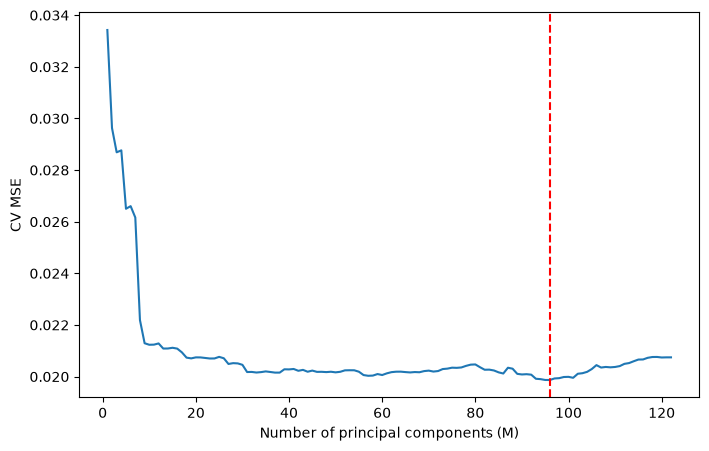

In [16]:
pcr = Pipeline([
    ("scaler", StandardScaler()),
    ("pca", PCA()),
    ("lr", LinearRegression()),
])

param_grid = {"pca__n_components": list(range(1, X_train.shape[1] + 1))}

pcr_cv = GridSearchCV(
    pcr,
    param_grid,
    cv=KFold(n_splits=10, shuffle=True, random_state=42),
    scoring="neg_mean_squared_error",
    n_jobs=-1,
)
pcr_cv.fit(X_train, y_train)

best_M = pcr_cv.best_params_["pca__n_components"]
pcr_pred = pcr_cv.predict(X_test)
pcr_mse = mean_squared_error(y_test, pcr_pred)

print("Best M:", best_M)
print("CV MSE at best M:", -pcr_cv.best_score_)
print("Test MSE:", pcr_mse)
print("Test RMSE:", np.sqrt(pcr_mse))

cv_mse = -pcr_cv.cv_results_["mean_test_score"]

plt.figure(figsize=(8, 5))
plt.plot(param_grid["pca__n_components"], cv_mse)
plt.axvline(best_M, color="red", linestyle="--")
plt.xlabel("Number of principal components (M)")
plt.ylabel("CV MSE")
plt.show()

results["PCR"] = pcr_mse

### (j) Fit a boosting tree

In [17]:
alpha_grid = [0, 0.001, 0.01, 0.1, 1, 10, 100]

xgb_model = xgb.XGBRegressor(
    objective="reg:squarederror",
    n_estimators=300,
    learning_rate=0.05,
    max_depth=3,
    subsample=0.8,
    colsample_bytree=0.8,
    reg_lambda=0,
    random_state=42,
    n_jobs=-1,
)

xgb_cv = GridSearchCV(
    xgb_model,
    {"reg_alpha": alpha_grid},
    cv=KFold(n_splits=10, shuffle=True, random_state=42),
    scoring="neg_mean_squared_error",
    n_jobs=1,
)
xgb_cv.fit(X_train, y_train)

best_alpha_xgb = xgb_cv.best_params_["reg_alpha"]
xgb_pred = xgb_cv.predict(X_test)
xgb_mse = mean_squared_error(y_test, xgb_pred)

print("Best alpha (L1):", best_alpha_xgb)
print("CV MSE at best alpha:", -xgb_cv.best_score_)
print("Test MSE:", xgb_mse)
print("Test RMSE:", np.sqrt(xgb_mse))

print(pd.DataFrame({"alpha": alpha_grid, "cv_mse": -xgb_cv.cv_results_["mean_test_score"]}))

results["XGBoost (L1)"] = xgb_mse
print(pd.Series(results).sort_values())

Best alpha (L1): 0.1
CV MSE at best alpha: 0.019535381784654297
Test MSE: 0.01615261346260861
Test RMSE: 0.127092932386536
     alpha    cv_mse
0    0.000  0.019989
1    0.001  0.019923
2    0.010  0.019661
3    0.100  0.019535
4    1.000  0.019633
5   10.000  0.021157
6  100.000  0.056727
XGBoost (L1)            0.016153
Ridge                   0.017541
LASSO                   0.017737
LASSO (standardized)    0.017839
Linear                  0.018142
PCR                     0.018425
dtype: float64
